In [ ]:
import pandas as pd
#- import pandas as pd carga la librería de tablas. pd es el nombre corto habitual.


In [ ]:
felled = pd.read_csv("../../train/felled_trees.csv")
felled.shape
print(felled.shape)

#- pd.read_csv(...) lee el archivo y lo guarda como una tabla llamada felled (un DataFrame).
#- La ruta ../train/... sube una carpeta desde notebooks/ y entra en train/. Por eso funciona desde el notebook.
#- felled.shape devuelve una pareja (filas, columnas). En Jupyter, la última línea de una celda se muestra sin necesidad de print.

(540, 12)


In [9]:
print(felled.dtypes)
print(felled.isna().sum())

#- felled.dtypes muestra el tipo de cada columna. Una columna numérica debería salir como float64 o int64. Si aparece como object, es que hay texto mezclado con números, y eso suele ser un problema de datos.
#- felled.isna().sum() cuenta cuántos valores faltan en cada columna. isna() marca cada celda como verdadera si está vacía, y sum() suma esas marcas por columna.


tree_id                 str
crew                    str
survey_batch          int64
east                float64
north               float64
altitude_m            int64
aspect                  str
spruce_share          int64
water_deficit_mm      int64
diameter_cm         float64
height_m            float64
biomass_kg          float64
dtype: object
tree_id              0
crew                 0
survey_batch         0
east                 0
north                0
altitude_m           0
aspect               0
spruce_share         0
water_deficit_mm     0
diameter_cm          0
height_m            40
biomass_kg           0
dtype: int64


In [10]:
felled.describe()
#Esto lo estamos hacienod ya que existen datos centinelas, es decir datos que el data set maneja como no validos, pero python si los considera como uno, es por eso que estamos limpiando priemro la data, mediante este comando
#- describe() calcula para cada columna numérica el count, la mean (media), la std (desviación estándar), el min (mínimo), los percentiles 25%, 50% (la mediana) y 75%, y el max (máximo).
#- Un centinela como -999 o 0 aparece como un min muy alejado del resto. Por eso lo que buscamos es el min de cada columna.

,survey_batch,east,north,altitude_m,spruce_share,water_deficit_mm,diameter_cm,height_m,biomass_kg
count,540.000000,5.400000e+02,5.400000e+02,540.000000,540.000000,540.000000,540.000000,500.000000,540.000000
mean,2.477778,2.645426e+06,1.195552e+06,1210.066667,74.444444,116.137037,94.500556,24.300000,472.699630
std,1.141829,6.663250e+02,6.138694e+02,141.929401,18.179344,21.140306,120.348990,6.961967,359.539798
min,1.000000,2.644113e+06,1.194112e+06,908.000000,35.000000,68.000000,1.600000,0.000000,30.400000
25%,1.000000,2.644911e+06,1.195098e+06,1102.750000,65.000000,104.000000,24.800000,20.900000,188.675000
50%,2.000000,2.645487e+06,1.195591e+06,1219.000000,75.000000,117.000000,33.350000,25.450000,373.700000
75%,4.000000,2.645974e+06,1.196084e+06,1315.250000,90.000000,132.000000,130.500000,28.900000,689.075000
max,4.000000,2.646593e+06,1.196593e+06,1451.000000,100.000000,156.000000,465.000000,41.800000,1671.900000


In [ ]:
print((felled["height_m"] == 0).sum())
print((felled["diameter_cm"] > 100).sum())
print(felled.loc[felled["diameter_cm"] > 100, ["tree_id", "diameter_cm", "height_m", "biomass_kg"]].head(10))


#PROMPT

#height_m: el min es 0.0. Un árbol de 0 m no es posible, así que ese 0 es casi seguro un centinela de "no medido". Además hay 40 celdas vacías (count 500 frente a 540). Son dos problemas distintos que hay que tratar por separado.

# diameter_cm: aquí está la señal más fuerte. La mediana es 33 cm, pero el percentil 75 es 130 cm y el máximo es 465 cm. Un abeto de 4,65 m de diámetro no es realista en el Prealpes suizos. Ese salto sugiere que parte de los valores está en otra unidad, por ejemplo milímetros, en lugar de centímetros. Es uno de los problemas típicos del enunciado (mixed units), pero todavía no lo hemos demostrado.
#- (felled["height_m"] == 0) compara cada celda con 0 y devuelve True o False. .sum() cuenta los True, es decir, cuántos ceros hay.
#- La segunda línea cuenta cuántos diámetros superan 100 cm.
#- La tercera muestra 10 de esos árboles, con su altura y su biomasa. .loc[filas, columnas] filtra filas y elige columnas.

18
136
    tree_id  diameter_cm  height_m  biomass_kg
4   T779732        254.0      24.9       298.8
8   T915796        158.0      15.3        73.4
9   T684412        252.0      21.0       230.4
11  T523081        154.0      17.2        72.2
12  T521524        316.0      27.9       588.0
13  T592760        174.0      19.2        80.8
15  T885604        394.0      30.2       731.4
21  T880797        224.0      20.9       218.7
27  T329603        394.0      30.3       795.6
30  T351938        459.0       NaN      1416.9


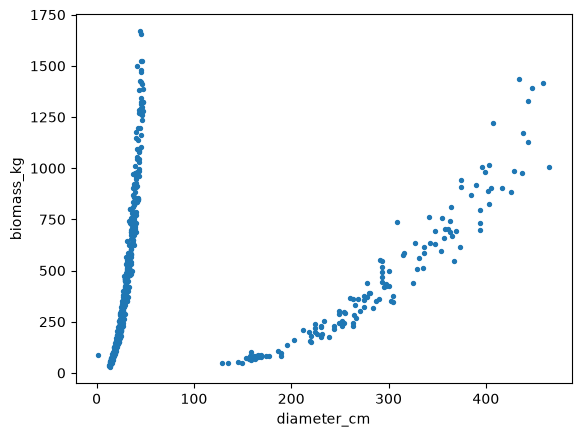

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(felled["diameter_cm"], felled["biomass_kg"], s=8)
plt.xlabel("diameter_cm")
plt.ylabel("biomass_kg")
plt.show()

#- matplotlib.pyplot es la librería de gráficos. plt es su nombre corto habitual.
#- scatter dibuja un punto por árbol, con diámetro en el eje horizontal y biomasa en el vertical. s=8 hace los puntos pequeños.
#- xlabel y ylabel ponen el nombre de cada eje.

In [18]:

pd.crosstab(felled["crew"], felled["diameter_cm"] > 100)
pd.crosstab(felled["survey_batch"], felled["diameter_cm"] > 100)

#- diameter_cm > 100 devuelve True o False por fila.
#- pd.crosstab(a, b) cuenta cuántas filas caen en cada combinación de a y b. Cada fila de la tabla es un valor de crew (o survey_batch), y las columnas son False (diámetro normal) y True (diámetro mayor de 100).


diameter_cm,False,True
survey_batch,,
1,106,37
2,107,30
3,88,31
4,103,38


In [ ]:
pd.crosstab(felled["crew"], felled["height_m"] == 0)
pd.crosstab(felled["crew"], felled["height_m"].isna())

height_m,False,True
crew,,
A,115,11
B,128,8
C,137,10
D,120,11


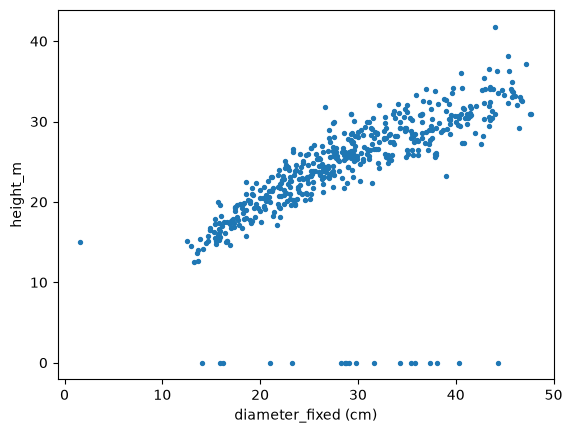

In [ ]:
felled["diameter_fixed"] = felled["diameter_cm"].where(felled["crew"] != "B", felled["diameter_cm"] / 10)
plt.scatter(felled["diameter_fixed"], felled["height_m"], s=8)
plt.xlabel("diameter_fixed (cm)")
plt.ylabel("height_m")
plt.show()

#- .where(condición, valor) mantiene el valor original donde la condición es verdadera y usa el segundo valor donde es falsa. Aquí: si el equipo no es B, mantiene el diámetro; si es B, usa el diámetro entre 10.
#- diameter_fixed es una columna nueva. El original no se modifica, y eso es buena práctica para poder comparar antes y después.

In [24]:
felled[felled["diameter_cm"] < 5]

,tree_id,crew,survey_batch,east,north,altitude_m,aspect,spruce_share,water_deficit_mm,diameter_cm,height_m,biomass_kg,diameter_fixed
113,T742819,A,4,2645662.7,1195472.0,1282,E,90,119,1.6,15.0,85.7,1.6


In [ ]:
import matplotlib.pyplot as plt
from bark.clean_shared import clean_shared
from bark.clean_felled import clean_felled, fit_estimators, estimate_missing

# Step 1: repair the data with the rules in the team's code (not hand fixes).
# clean_shared fixes the aspect spellings; clean_felled applies the three felled rules.
# Both return copies, so `felled` (the raw data) is never changed.
base = clean_felled(clean_shared(felled))

print("missing diameter:", base["diameter_cm"].isna().sum())
print("missing height:  ", base["height_m"].isna().sum())

## Estimating the missing values

We fill the gaps with two linear models on the **logarithms**. This is the same power-law idea as Task 2:
biomass ≈ a × d^b × h^c. Taking logs turns it into a straight line, so `LinearRegression` can fit it.

- The models are fitted in `fit_estimators()` on rows where diameter, height and biomass are observed.
- The rows we are trying to fill are never used to fit the models.
- `base` is never modified. `estimate_missing()` returns a filled copy.
- Only `train/` data is used. The same fitted models will be applied to `test/` later, but never refitted on it.

In [ ]:
# Step 2: fit the two models on the observed rows of train/.
models = fit_estimators(base)
print("fitted models:", list(models))

# Step 3: fill the missing diameter (1 row) and the missing heights (58 rows).
felled_clean = estimate_missing(base, models)

In [ ]:
# Check 1: no missing values should remain.
print("missing values left:", int(felled_clean.isna().sum().sum()))

# Check 2: the estimated values should look like the observed ones.
print(felled_clean[["diameter_cm", "height_m"]].describe())

# The tree that had 1.6 cm (a decimal error, see CLAUDE.md section 8) is now estimated:
print(felled_clean.loc[felled_clean["tree_id"] == "T742819", ["tree_id", "crew", "diameter_cm", "height_m", "biomass_kg"]])

In [ ]:
# Check 3: plot observed (blue) and estimated (red) trees together.
estimated = base["height_m"].isna() | base["diameter_cm"].isna()

plt.scatter(felled_clean.loc[~estimated, "diameter_cm"], felled_clean.loc[~estimated, "height_m"],
            s=8, label="observed")
plt.scatter(felled_clean.loc[estimated, "diameter_cm"], felled_clean.loc[estimated, "height_m"],
            s=14, color="red", label="estimated")
plt.xlabel("diameter_cm")
plt.ylabel("height_m")
plt.legend()
plt.show()

## Category columns (step A3)

Counts per category, on the raw file and after `clean_shared()`. The raw `aspect` column has the same
direction written in several ways, so we check it before and after the fix.

In [ ]:
# Raw categories: show the spellings as they are in the file.
for col in ["aspect", "crew", "survey_batch"]:
    print(felled[col].value_counts(dropna=False).to_string(), "\n")

# After clean_shared: aspect should now have only N, E, S and W.
print(clean_shared(felled)["aspect"].value_counts(dropna=False).to_string())

## Histograms (step A4)

One histogram per numeric column, after cleaning and estimation. The diameter histogram should now show one
cloud, not two.

In [ ]:
felled_clean.select_dtypes("number").hist(bins=30, figsize=(12, 9))
plt.tight_layout()
plt.show()

## Summary of the felled-trees analysis (Task 1, step A)

**What the data look like.** `train/felled_trees.csv` has 540 rows and 12 columns: 11 shared columns plus
`biomass_kg`. Column types are correct. Only `height_m` has empty cells (40 rows). No duplicate
rows or duplicate `tree_id`s.

**Problems found and how they are handled.**

1. **Diameters in millimetres for crew B** (136 rows). Evidence: all 136 diameters above 100 cm belong to
   crew B, and the scatter of biomass against diameter shows two separate clouds that line up after dividing
   by 10. Rule: divide crew B's diameters by 10 (`clean_felled`).
2. **Height 0 as a placeholder** (18 rows, spread over all crews). A tree cannot be 0 m tall. Rule: treat it
   as missing (`clean_felled`).
3. **Empty heights** (40 rows, spread over all crews). Rule: estimate them (`estimate_missing`).
4. **Impossible diameter 1.6 cm** (crew A, one row, `T742819`). Its biomass (85.7 kg) and height (15 m)
   both point to about 16 cm, so the value is most likely a decimal error. Rule: treat diameters below 5 cm as
   missing and estimate them from the other measurements. We do not correct single rows by hand.
5. **Inconsistent aspect spellings** (`S`, `South`, `s`, `SÜD`). The same direction written in several ways.
   Rule: normalise to N, E, S, W (`clean_shared`). Proposed for the whole team, see CLAUDE.md section 8.

**Estimation.** Two linear regressions on the logarithms, one for diameter and one for height, fitted only on
observed rows of `train/`. They are a power-law approximation of biomass, as in Task 2. Fitted R² values were
about 0.97 for the diameter model and 0.90 for the height model. The estimated diameter for `T742819` is
17.4 cm.

**What the plots show.** After the cleaning, diameter and height follow one clear increasing trend, and the
estimated points lie on that trend. Biomass against diameter forms one curved cloud instead of two.

**What is still open.**
- The estimation models are not yet saved to `code/models/`. They must be saved and reused by `predict.py`
  on `test/` and `test_exam/`, without refitting.
- `estimate_missing` raises an error if a row misses both diameter and height. This did not happen in `train/`,
  but it could happen in new data.
- The report section for these findings (A8) is not written yet.